<a href="https://colab.research.google.com/github/AlexCort67/PIA/blob/main/PIA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

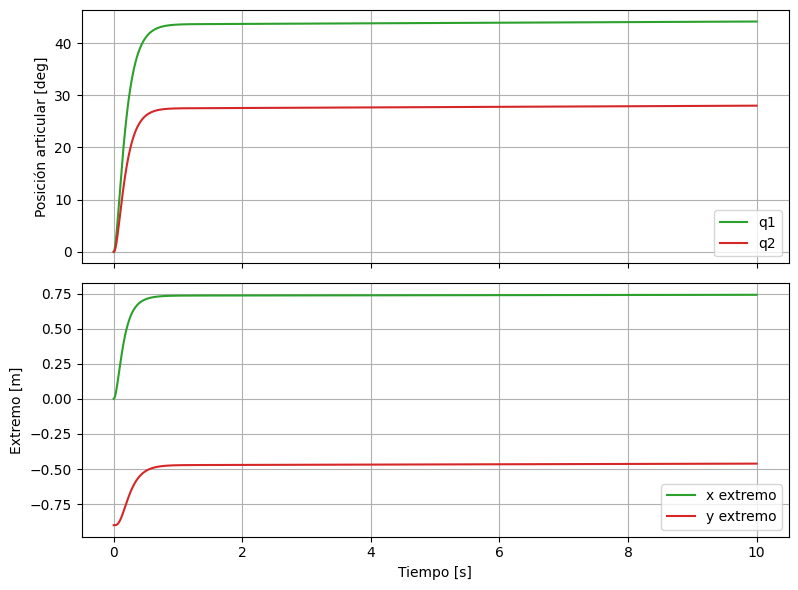

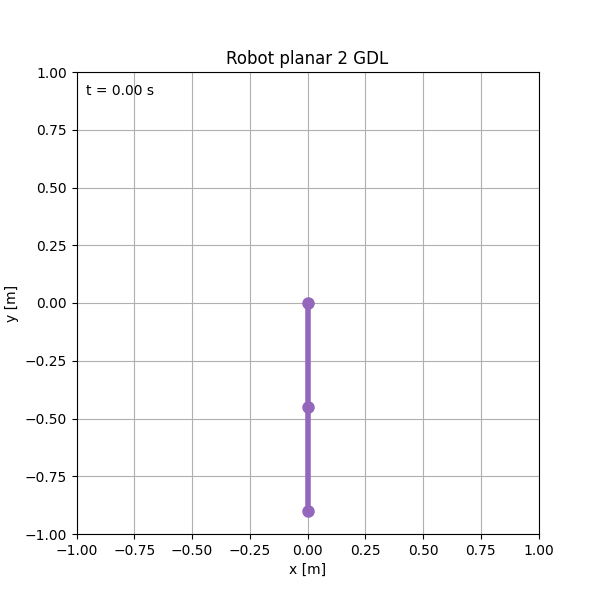

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import Image

# Parámetros del robot 2 GDL y control PD + gravedad
m1, m2, l1, l2, lc1, lc2, I1, I2, g = 23.902, 3.88, 0.45, 0.45, 0.091, 0.048, 1.266, 0.093, 9.81
b, fc, fe = np.array([2.288, 0.175]), np.array([7.17, 1.734]), np.array([8.45, 2.35])
q_des, Kp, Kd = np.array([np.pi/4, np.pi/6]), np.array([300.0, 40.0]), np.array([60.0, 8.0])

def M(q):
    c2 = np.cos(q[1])
    a, b_ = m2*lc2**2 + I2, m2*l1*lc2*c2
    return np.array([[m1*lc1**2 + m2*l1**2 + I1 + a + b_, a + b_], [a + b_, a]])

def C(q, qd):
    h = m2*l1*lc2*np.sin(q[1])
    return np.array([[-2*h*qd[1], -h*qd[1]], [h*qd[0], 0.0]])

def G(q):
    s1, s12 = np.sin(q[0]), np.sin(q[0] + q[1])
    return g*np.array([(lc1*m1 + m2*l1)*s1 + m2*lc2*s12, lc2*m2*s12])

def f_estado(t, x):
    q, qd = x[:2], x[2:]
    g_q, c_qd = G(q), C(q, qd) @ qd
    tv = Kp*(q_des - q) - Kd*qd + g_q
    f = b*qd + fc*np.sign(qd)
    reposo = np.abs(qd) < 1e-3
    f[reposo] = np.clip(tv - c_qd - g_q, -fe, fe)[reposo]
    return np.concatenate([qd, np.linalg.solve(M(q), tv - c_qd - g_q - f)])

# Simulación RK4 (10 s)
t = np.arange(0, 10.0 + 1e-3, 1e-3)
X = np.zeros((len(t), 4))
for k, tk in enumerate(t[:-1]):
    dt = t[k+1] - tk
    x = X[k]
    k1 = f_estado(tk, x)
    k2 = f_estado(tk + dt/2, x + dt/2*k1)
    k3 = f_estado(tk + dt/2, x + dt/2*k2)
    k4 = f_estado(tk + dt, x + dt*k3)
    X[k+1] = x + dt*np.clip(k1 + 2*k2 + 2*k3 + k4, -1e6, 1e6)/6

q1, q2 = X[:, 0], X[:, 1]
x1, y1 = l1*np.sin(q1), -l1*np.cos(q1)
x2, y2 = x1 + l2*np.sin(q1 + q2), y1 - l2*np.cos(q1 + q2)

# Gráficas (verde y rojo)
fig, ax = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
ax[0].plot(t, np.degrees(q1), color="tab:green", label="q1")
ax[0].plot(t, np.degrees(q2), color="tab:red", label="q2")
ax[0].set(ylabel="Posición articular [deg]"); ax[0].legend(); ax[0].grid()
ax[1].plot(t, x2, color="tab:green", label="x extremo")
ax[1].plot(t, y2, color="tab:red", label="y extremo")
ax[1].set(ylabel="Extremo [m]", xlabel="Tiempo [s]"); ax[1].legend(); ax[1].grid()
plt.tight_layout(); plt.show()

# Animación GIF (brazo morado)
fig2, ax2 = plt.subplots(figsize=(6, 6))
R = l1 + l2 + 0.1
ax2.set(xlim=(-R, R), ylim=(-R, R), aspect="equal", xlabel="x [m]", ylabel="y [m]", title="Robot planar 2 GDL")
ax2.grid()
link, = ax2.plot([], [], "o-", lw=4, color="tab:purple", markersize=8)
traza, = ax2.plot([], [], "--", lw=1, color="darkviolet")
txt = ax2.text(0.02, 0.95, "", transform=ax2.transAxes)

def update(i):
    link.set_data([0, x1[i], x2[i]], [0, y1[i], y2[i]])
    traza.set_data(x2[:i+1], y2[:i+1])
    txt.set_text(f"t = {t[i]:.2f} s")
    return link, traza, txt

FuncAnimation(fig2, update, frames=range(0, len(t), 50), interval=50, blit=True).save("robot_2gdl.gif", writer="pillow", fps=20)
plt.close(fig2)
Image("robot_2gdl.gif")